# Abstract: The Persistence of Momentum
The momentum effect—the empirical observation that relative performance tends to persist—represents a systematic challenge to the Efficient Market Hypothesis. Since Jegadeesh and Titman (1993), this phenomenon has been established as a universal market feature rather than an anomaly.

Theoretical Framework:

- Empirical Robustness: Cross-asset and cross-jurisdictional replication confirm that price trends are statistically persistent.
- Institutional Exploitation: The continued deployment of momentum strategies by quantitative funds validates the existence of exploitable return premiums in live markets.
- Behavioral Mechanism: The momentum premium arises from delayed information diffusion and investor herding, which facilitate gradual price discovery, contradicting the theory of instantaneous market adjustment.

In [1]:
# Add the project root (one level up from /research) to the path
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

# Libraries needed to run the code
from utils.bybit import BybitConnector
from utils.engine import *
from utils.indicators import *

client = BybitConnector(api_key="abc", api_secret="abc", testnet=False)
price = client.get_ohlcv("BTCUSDT", "1", 200)


# First Step: Proving Market Observation
RSI snapback speed has a strong correlation with MA acceleration.
- If MA acceleration > 0, RSI snapback speed is significantly faster on the long side.
- If MA acceleration < 0, RSI snapback speed is significantly faster on the short side.

| Strong Bull (Force_POS) | Sideway Market | Strong Bear (Force_NEG) |
| :---: | :---: | :---: |
| ![Strong Bull](./image/img_1.png) | ![Stop Trading](./image/img_3.png) | ![Strong Short](./image/img_2.png) |


In [2]:
atr = calculate_atr(price['high'], price['low'], price['close'], 7)
ma, ma_slope, ma_acceleration, rsi = get_market_kinematics(price['close'], atr)

min_len = len(ma)
df = pd.DataFrame({
    'rsi': rsi,
    'ma_slope': ma_slope[-min_len:],
    'acc': ma_acceleration[-min_len:]
})

# 4. Run the Analysis
stats = analyze_regime_speed(df)

# 5. Output Results
print(stats.groupby('regime')['bars_to_neutral'].agg(['mean', 'count', 'std']))

                                mean  count       std
regime                                               
Long_Slope_DOWN_Force_NEG   2.636364     22  1.915984
Long_Slope_DOWN_Force_POS   3.750000     12  2.220770
Long_Slope_UP_Force_NEG     6.000000      1       NaN
Short_Slope_DOWN_Force_NEG  2.208333     24  1.413573
Short_Slope_DOWN_Force_POS  2.533333     15  1.597617


The momentum strategy demonstrates efficacy contingent upon a robust regime-detection system, specifically classifying market states as strongly bullish, sideways, or strongly bearish. The lack of statistical edge observed in highly efficient markets during generic testing—where mean recovery times converge toward 3 bar—highlights the necessity of regime-specific analysis.

However, a quantifiable edge emerges when confirming the confluence of MA slope and kinetic force (acceleration), as evidenced in the following comparative analysis.

![Prove](./image/img_4.png)

This alignment minimizes recovery variance, suggesting that RSI mean reversion is structurally optimized when directional bias and kinetic velocity are synchronized.

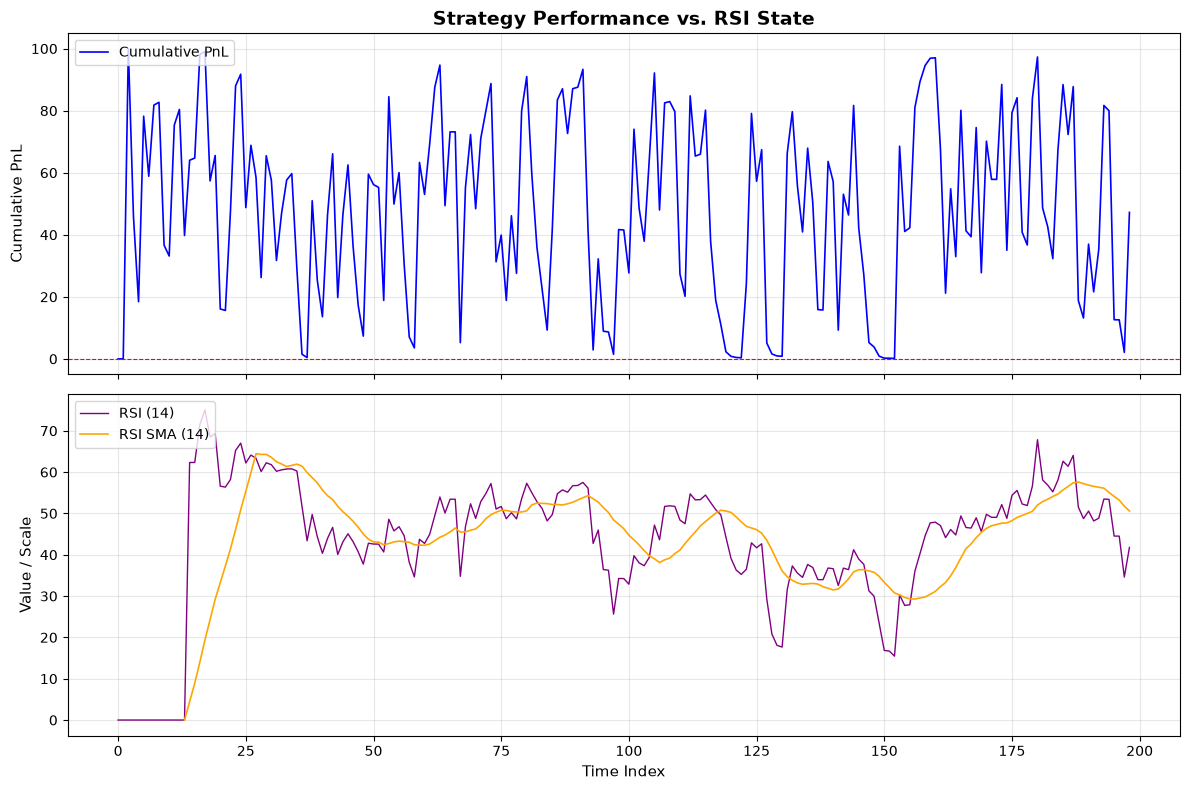

In [4]:
price_clean = np.asanyarray(price['close'], dtype=float)
rsi_2 = get_wilders_rsi(np.diff(price_clean), 2)
rsi_14 = get_wilders_rsi(np.diff(price_clean), 14)
rsi_14_sma = sma(rsi_14, 14)

# Call it with your variables, explicitly passing labels so the chart is clear
plot_two(
    primary_data=rsi_2, 
    secondary_data_1=rsi_14, 
    secondary_data_2=rsi_14_sma,
    primary_label="Cumulative PnL",
    secondary_label_1="RSI (14)",
    secondary_label_2="RSI SMA (14)",
    title="Strategy Performance vs. RSI State"
)

# Second Step: Automated Feature Engineering and ML prediction for RSI(14) breakout of SMA(14) period

Consider that the market is random walk, the fastest way to find alpha is by creating automated feature engineering to quickly discover variables that have relationships with target variable. RSI(14) > SMA(14) is a smoothed representation of MA acceleration.

# Third Step: Creating Momentum Composite
Selection system: two approaches
- Create an algo that performs sentiment and fundamental analysis on crypto, giving it a score then we pick the best performers
- Identify by price action. Price movement 15m, 1hr, 4hr all positive. Then volume.